# Libraries

In [17]:
%pip install scikit-learn
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [18]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    auc
)

# Loading data


In [19]:
train_df = pd.read_csv("../data/train.csv")
val_df = pd.read_csv("../data/validation.csv")
test_df = pd.read_csv("../data/test.csv")

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

Train shape: (198608, 31)
Validation shape: (42559, 31)
Test shape: (42559, 31)


# Separating features and target

In [20]:
X_train = train_df.drop(columns=["Class"])
y_train = train_df["Class"]

X_val = val_df.drop(columns=["Class"])
y_val = val_df["Class"]

X_test = test_df.drop(columns=["Class"])
y_test = test_df["Class"]

print("Training fraud cases:", y_train.sum())
print("Validation fraud cases:", y_val.sum())
print("Test fraud cases:", y_test.sum())

Training fraud cases: 366
Validation fraud cases: 55
Test fraud cases: 52


# Scaling

Applying scaling as logistic regression works better with scaled numercial variables as the variables will be in the comparable range

In [21]:
# using standard scaler as the distribution of the features are roughly symmetrical
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Training the baseline model

In [22]:
log_reg = LogisticRegression(
    max_iter=1000, # maximum iteration us set as 1000
    random_state=42 # random state is fixed as 42 for reproducibility
)

log_reg.fit(X_train_scaled, y_train) # fitting the logistic regression

print("Baseline Logistic Regression trained successfully.")

Baseline Logistic Regression trained successfully.


# Generating prediction probabilities

Prediction probabilities are calculated instead of prediction classes for utilising  pr- auc and average precision to evaluate the model

In [23]:
y_val_proba = log_reg.predict_proba(X_val_scaled)[:, 1]

#log_reg.predict_proba() calculates the predicted probabilities for each class.
#X_val_scaled supplies the scaled validation features to the trained model.
#[:, 1] selects the probability of Class 1 (fraud) for every transaction.
#y_val_proba stores these fraud probabilities.
y_test_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

print("First 10 validation fraud probabilities:")
print(y_val_proba[:10])

First 10 validation fraud probabilities:
[1.60479103e-03 1.03473111e-04 1.62594454e-04 1.08771673e-04
 6.58113817e-05 9.19952879e-05 1.04937975e-03 3.89143385e-05
 1.02149941e-04 1.92992803e-04]


# Evaluate PR-AUC and Average Precision

In [24]:
# Average Precision
val_ap = average_precision_score(y_val, y_val_proba) # calculates the Average Precision (AP) score of your 
#Logistic Regression model on the validation dataset
test_ap = average_precision_score(y_test, y_test_proba)

# Precision–Recall curves
val_precision, val_recall, _ = precision_recall_curve(
    y_val, y_val_proba
)

test_precision, test_recall, _ = precision_recall_curve(
    y_test, y_test_proba
)


## Plotting PR- AUC curves

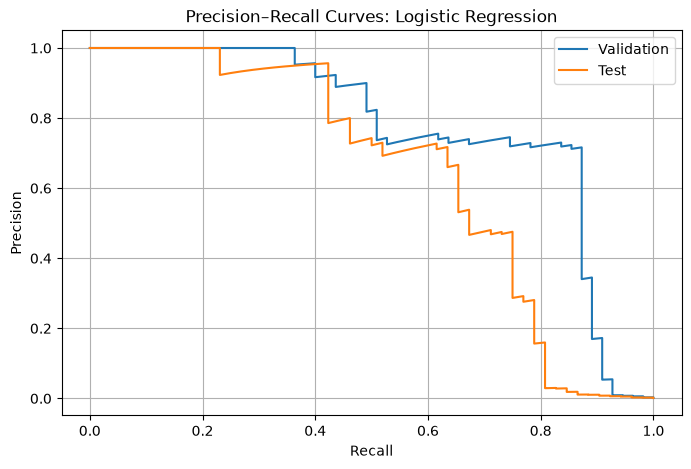

In [25]:


plt.figure(figsize=(8, 5))

# Validation PR curve
plt.plot(
    val_recall,
    val_precision,
    label="Validation"
)

# Test PR curve
plt.plot(
    test_recall,
    test_precision,
    label="Test"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curves: Logistic Regression")
plt.legend()
plt.grid(True)

plt.show()


## Area under the PR - AUC curve

In [26]:
# Trapezoidal area under the PR curve
val_pr_auc = auc(val_recall, val_precision)
test_pr_auc = auc(test_recall, test_precision)

benchmark = pd.DataFrame({
    "Dataset": ["Validation", "Test"],
    "PR-AUC": [val_pr_auc, test_pr_auc],
    "Average Precision": [val_ap, test_ap]
})

benchmark

,Dataset,PR-AUC,Average Precision
0,Validation,0.772715,0.773999
1,Test,0.642622,0.644247
